# Discrete-Time Stochastic Riccati Optimal Control (DT-LTI)

## Problem setup

We consider a discrete-time linear time-invariant (DT-LTI) system with **additive process noise**:

$$x_{k+1} = A x_k + B u_k + w_k, \qquad w_k \sim \mathcal{N}(0, W)$$

and the quadratic cost

$$J = \mathbb{E}\!\left[\sum_{k=0}^{N-1}\big(x_k^\top Q x_k + u_k^\top R u_k\big) + x_N^\top Q_f x_N\right]$$

---

## Optimal control law

The optimal feedback is linear in the state:

$$u_k = -K_k x_k, \qquad K_k = (R + B^\top P_{k+1} B)^{-1} B^\top P_{k+1} A$$

where the **Riccati matrix** $P_k$ is computed **backward** from the terminal condition $P_N = Q_f$:

$$P_k = Q + A^\top P_{k+1} A - A^\top P_{k+1} B\,(R + B^\top P_{k+1} B)^{-1} B^\top P_{k+1} A$$

For an **infinite horizon**, iterating this recursion until convergence gives the steady-state $P_\infty$ (solution of the Discrete Algebraic Riccati Equation, DARE), and the constant gain

$$K_\infty = (R + B^\top P_\infty B)^{-1} B^\top P_\infty A.$$

---

## Certainty equivalence

A key result: for additive noise, **the optimal gain does not depend on $W$**. The controller is identical to the deterministic LQR gain. The noise only affects:

- the *trajectory* (through the injected randomness), and
- the *expected cost* (through the stationary covariance $\Sigma$ satisfying $\Sigma = A_{cl}\Sigma A_{cl}^\top + W$, with $A_{cl} = A - BK$).

This is why we can compute $K$ via `solve_discrete_are(A, B, Q, R)` alone.

---

## What the code below does

1. Defines a 2-state, 1-input DT-LTI system with additive noise covariance $W$.
2. Implements the **finite-horizon backward Riccati recursion** (`riccati_backward`).
3. Solves the **steady-state DARE** with `scipy.linalg.solve_discrete_are` and checks closed-loop stability via $|\lambda(A-BK)| < 1$.
4. Simulates one closed-loop trajectory and plots states, control, and state norm.
5. Runs a **Monte Carlo** (many noise realizations) and plots the mean $\pm 2\sigma$ envelope.
6. Plots convergence of the finite-horizon $P_k$ to $P_\infty$ (validates the infinite-horizon approximation).

---

## Notes / extensions

- To add **multiplicative noise** (e.g. $x_{k+1} = A x_k + B u_k + \sum_i (A_i x_k + B_i u_k)\,\xi_{k,i}$), the Riccati recursion changes and $K$ **does** depend on the noise statistics.
- For **output feedback without an observer**, replace $x_k$ with a state estimate or use a static output gain; the Riccati structure changes.
- You can experiment by changing $A$, $B$, $Q$, $R$, or $W$ in the code cell — the plots will update automatically.

Controllability matrix rank: 2 (n = 2 )

Steady-state P:
 [[ 2.51620072 -2.42462931]
 [-2.42462931  5.19401424]]

Steady-state gain K:
 [[0.91879965 0.19740452]]

Closed-loop eigenvalues: [0.07365752 0.90884057]
|eigs|: [0.07365752 0.90884057]

Accumulated quadratic cost over 200 steps: 100.792


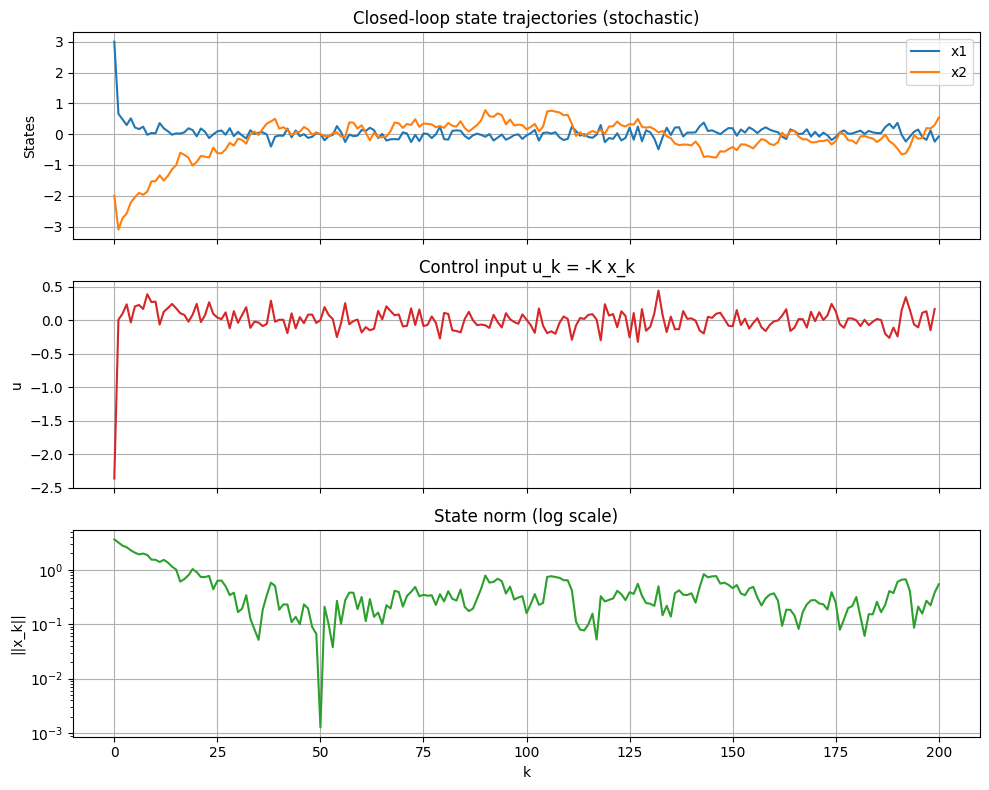

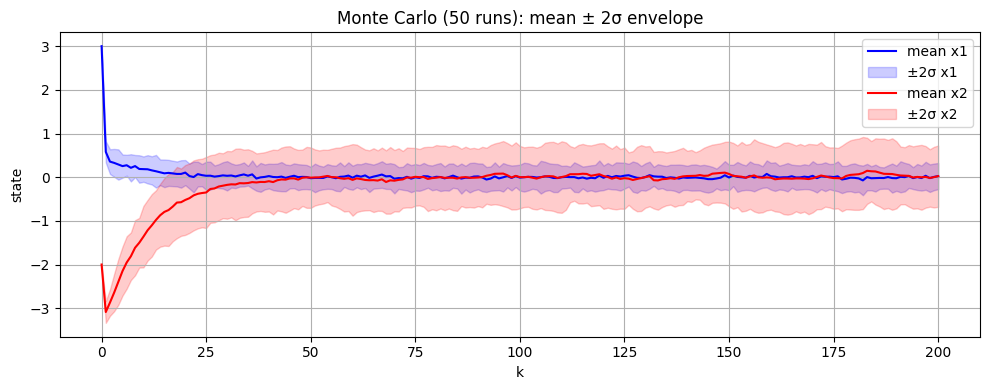

In [2]:
# ============================================================
# Discrete-Time Stochastic Riccati Optimal Control (DT-LTI)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_discrete_are
np.random.seed(42)

# ---------- 1. System definition ----------
# Example: unstable-ish 2D system, 1 input
A = np.array([[1.05, 0.10],
              [0.00, 0.95]])
B = np.array([[1.0],
              [0.5]])
n, m = B.shape

# Noise covariance (additive process disturbance)
W = np.array([[0.02, 0.00],
              [0.00, 0.02]])

# Cost matrices
Q  = np.array([[1.0, 0.0],
               [0.0, 1.0]])
R  = np.array([[0.1]])          # control penalty
Qf = Q.copy()                    # terminal cost (for finite horizon)

# Check controllability
Ctrb = np.hstack([B, A @ B])
print("Controllability matrix rank:", np.linalg.matrix_rank(Ctrb), "(n =", n, ")")

# ---------- 2. Backward Riccati recursion (finite horizon) ----------
def riccati_backward(A, B, Q, R, Qf, N):
    """Return list P[0..N] with P[N]=Qf, and gains K[0..N-1]."""
    P_list = [None] * (N + 1)
    K_list = [None] * N
    P_list[N] = Qf.copy()
    for k in range(N - 1, -1, -1):
        P_next = P_list[k + 1]
        S = R + B.T @ P_next @ B
        K = np.linalg.solve(S, B.T @ P_next @ A)
        P = Q + A.T @ P_next @ A - A.T @ P_next @ B @ K
        P = 0.5 * (P + P.T)          # symmetrize
        P_list[k] = P
        K_list[k] = K
    return P_list, K_list

# ---------- 3. Steady-state (infinite-horizon) Riccati ----------
# Solve Discrete Algebraic Riccati Equation
P_ss = solve_discrete_are(A, B, Q, R)
K_ss = np.linalg.solve(R + B.T @ P_ss @ B, B.T @ P_ss @ A)

# Also demonstrate convergence of the recursion to P_ss
_, _ = riccati_backward(A, B, Q, R, P_ss, 1)  # just a sanity call
print("\nSteady-state P:\n", P_ss)
print("\nSteady-state gain K:\n", K_ss)

# Closed-loop eigenvalues (deterministic part)
Acl = A - B @ K_ss
print("\nClosed-loop eigenvalues:", np.linalg.eigvals(Acl))
print("|eigs|:", np.abs(np.linalg.eigvals(Acl)))

# ---------- 4. Simulate closed loop ----------
T_sim = 200
x = np.array([3.0, -2.0])         # initial condition
X = np.zeros((n, T_sim + 1))
U = np.zeros((m, T_sim))
X[:, 0] = x

# State and input costs accumulated
cost = 0.0

for k in range(T_sim):
    u = -K_ss @ x
    w = np.random.multivariate_normal(np.zeros(n), W)
    x_next = A @ x + B @ u + w

    U[:, k] = u
    cost += x @ Q @ x + u @ R @ u

    x = x_next
    X[:, k + 1] = x
cost += x @ Qf @ x

print(f"\nAccumulated quadratic cost over {T_sim} steps: {cost:.3f}")

# ---------- 5. Plotting ----------
t = np.arange(T_sim + 1)
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(t, X[0, :], label="x1")
axs[0].plot(t, X[1, :], label="x2")
axs[0].set_ylabel("States")
axs[0].set_title("Closed-loop state trajectories (stochastic)")
axs[0].legend(); axs[0].grid(True)

axs[1].plot(np.arange(T_sim), U[0, :], color="tab:red")
axs[1].set_ylabel("u")
axs[1].set_title("Control input u_k = -K x_k")
axs[1].grid(True)

axs[2].semilogy(t, np.linalg.norm(X, axis=0) + 1e-12, color="tab:green")
axs[2].set_ylabel("||x_k||")
axs[2].set_xlabel("k")
axs[2].set_title("State norm (log scale)")
axs[2].grid(True)

plt.tight_layout()
plt.show()

# ---------- 6. Monte Carlo: average behavior ----------
N_mc = 50
X_mc = np.zeros((N_mc, n, T_sim + 1))
for i in range(N_mc):
    x = np.array([3.0, -2.0])
    X_mc[i, :, 0] = x
    for k in range(T_sim):
        u = -K_ss @ x
        w = np.random.multivariate_normal(np.zeros(n), W)
        x = A @ x + B @ u + w
        X_mc[i, :, k + 1] = x

mean_x = X_mc.mean(axis=0)
std_x  = X_mc.std(axis=0)

plt.figure(figsize=(10, 4))
plt.plot(t, mean_x[0], 'b',  label="mean x1")
plt.fill_between(t, mean_x[0]-2*std_x[0], mean_x[0]+2*std_x[0],
                 color='b', alpha=0.2, label="±2σ x1")
plt.plot(t, mean_x[1], 'r',  label="mean x2")
plt.fill_between(t, mean_x[1]-2*std_x[1], mean_x[1]+2*std_x[1],
                 color='r', alpha=0.2, label="±2σ x2")
plt.xlabel("k"); plt.ylabel("state")
plt.title(f"Monte Carlo ({N_mc} runs): mean ± 2σ envelope")
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()



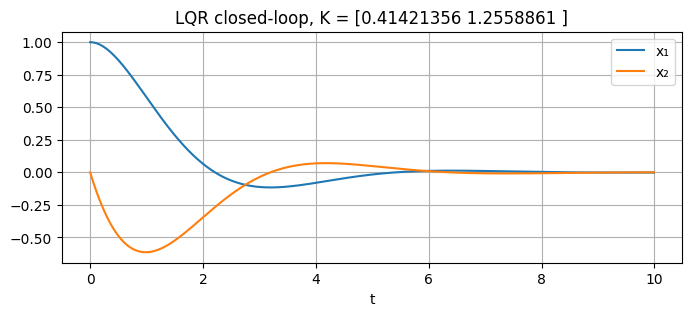

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are

# === System: inverted pendulum on cart (linearized) or any (A,B) ===
# Example: double integrator (mass-spring-damper, m=1, k=1, c=0.1)
A = np.array([[0., 1.],
              [-1., -0.1]])
B = np.array([[0.],
              [1.]])

# === LQR weights ===
Q = np.eye(2)      # state penalty
R = np.array([[1.]])  # input penalty

# === Solve continuous-time Riccati equation ===
P = solve_continuous_are(A, B, Q, R)
K = np.linalg.solve(R, B.T @ P)   # LQR gain

# === Closed-loop dynamics ===
Acl = A - B @ K

# === Simulation ===
x0 = np.array([1.0, 0.0])   # initial state
dt, T = 0.01, 10.0
t = np.arange(0, T, dt)
x = np.zeros((len(t), 2)); x[0] = x0
for i in range(1, len(t)):
    u = -K @ x[i-1]
    x[i] = x[i-1] + dt * (A @ x[i-1] + B.flatten() * u)

# === Plot ===
plt.figure(figsize=(8, 3))
plt.plot(t, x[:, 0], label='x₁')
plt.plot(t, x[:, 1], label='x₂')
plt.xlabel('t'); plt.grid(); plt.legend()
plt.title(f'LQR closed-loop, K = {K.ravel()}')
plt.show()

# Continuous-Time LQR Design for a 3-State, 2-Input LTI System

## 1. Problem Statement

Consider the continuous-time linear time-invariant (LTI) system

$$
\dot{\mathbf{x}}(t) = A\,\mathbf{x}(t) + B\,\mathbf{u}(t), \qquad
\mathbf{x}\in\mathbb{R}^3,\;\; \mathbf{u}\in\mathbb{R}^2,
$$

with $A \in \mathbb{R}^{3\times 3}$ and $B \in \mathbb{R}^{3\times 2}$ given by your assigned variant (see Section 3).

**Goal:** design a state-feedback controller $\mathbf{u} = -K\mathbf{x}$ that minimizes the infinite-horizon quadratic cost

$$
J = \int_{0}^{\infty} \left( \mathbf{x}^\top Q\,\mathbf{x} + \mathbf{u}^\top R\,\mathbf{u} \right) dt,
\qquad Q = Q^\top \succeq 0,\;\; R = R^\top \succ 0 .
$$

---

## 2. Tasks

1. **Build** $A$ and $B$ from the variant specification.
2. **Choose** $Q \succeq 0$ ($3\times3$) and $R \succ 0$ ($2\times2$), and briefly justify the choice.
3. **Solve** the continuous-time algebraic Riccati equation (CARE) for $P$:
   $$
   A^\top P + P A - P B R^{-1} B^\top P + Q = 0
   $$
   using `scipy.linalg.solve_continuous_are`.
4. **Compute** the optimal gain:
   $$
   K = R^{-1} B^\top P
   $$
5. **Simulate** the closed-loop system
   $$
   \dot{\mathbf{x}} = (A - BK)\,\mathbf{x}, \qquad \mathbf{x}(0)=\mathbf{x}_0=\begin{bmatrix}1\\1\\1\end{bmatrix},
   \qquad t\in[0,\,10]\ \text{s}
   $$
   using `scipy.integrate.solve_ivp` or `scipy.signal.lsim`.
6. **Plot** the states $x_1(t),\,x_2(t),\,x_3(t)$ and the control inputs $\mathbf{u}(t) = -K\mathbf{x}(t)$.
7. **Report** the gain $K$ and the closed-loop poles, i.e. the eigenvalues of $A-BK$.

---


## 3. Variants

Pick the one assigned to you.

| Variant | $A$ | $B$ | Note |
|:---:|:---:|:---:|:---|
| **V1** | $\begin{bmatrix}0&1&0\\0&0&1\\-1&-2&-3\end{bmatrix}$ | $\begin{bmatrix}0&0\\1&0\\0&1\end{bmatrix}$ | |
| **V2** | $\begin{bmatrix}0&1&0\\0&0&1\\-2&-3&-1\end{bmatrix}$ | $\begin{bmatrix}0&0\\0&1\\1&0\end{bmatrix}$ | |
| **V3** | $\begin{bmatrix}-1&1&0\\0&-2&1\\0&0&-3\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}$ | |
| **V4** | $\begin{bmatrix}0&1&0\\0&0&1\\-4&-4&-1\end{bmatrix}$ | $\begin{bmatrix}0&1\\1&0\\0&0\end{bmatrix}$ | |
| **V5** | $\begin{bmatrix}0&1&0\\-1&0&0\\0&0&-2\end{bmatrix}$ | $\begin{bmatrix}0&0\\1&0\\0&1\end{bmatrix}$ | |
| **V6** | $\begin{bmatrix}-2&1&0\\0&-1&1\\0&0&-3\end{bmatrix}$ | $\begin{bmatrix}1&0\\1&1\\0&1\end{bmatrix}$ | |
| **V7** | $\begin{bmatrix}0&1&0\\0&0&1\\-6&-11&-6\end{bmatrix}$ | $\begin{bmatrix}0&0\\1&0\\0&1\end{bmatrix}$ |  |
| **V8** | $\begin{bmatrix}0&0&1\\1&0&0\\0&1&0\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\1&0\end{bmatrix}$ | |
| **V9** | $\begin{bmatrix}-1&0&1\\0&-2&0\\1&0&-1\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\0&0\end{bmatrix}$ | |
| **V10** | $\begin{bmatrix}0&1&0\\0&0&1\\1&0&0\end{bmatrix}$ | $\begin{bmatrix}0&0\\1&0\\0&1\end{bmatrix}$ | |
| **V11** | $\begin{bmatrix}-3&1&0\\1&-3&1\\0&1&-3\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}$ | |
| **V12** | $\begin{bmatrix}0&2&0\\0&0&3\\-1&-2&-3\end{bmatrix}$ | $\begin{bmatrix}0&1\\1&0\\0&1\end{bmatrix}$ | |
| **V13** | $\begin{bmatrix}-1&1&0\\1&-1&1\\0&1&-1\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\0&0\end{bmatrix}$ | |
| **V14** | $\begin{bmatrix}0&1&0\\0&0&1\\-3&-2&-1\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\1&0\end{bmatrix}$ | |
| **V15** | $\begin{bmatrix}-2&0&0\\0&-3&1\\0&0&-1\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&0\\0&1\end{bmatrix}$ |  |
| **V16** | $\begin{bmatrix}0&1&0\\0&0&1\\-1&-1&-1\end{bmatrix}$ | $\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}$ | |